# Librerías, constantes y cosmologias

In [14]:
import numpy as np
from scipy.integrate import quad

import matplotlib.pyplot as plt

from classy import Class


# Defino la cosmología
params = {
    # ΛCDM (Planck 2018)
    'h': 0.6736,              # H0 = 100 h km/s/Mpc
    'omega_b': 0.02237,       # Ω_b h²
    'omega_cdm': 0.1200,      # Ω_cdm h²
    'A_s': 2.1e-9,            # amplitud del espectro primordial
    'n_s': 0.9649,            # índice espectral
    'tau_reio': 0.0544,       # profundidad óptica de reionización
    # qué calcular
    'output': 'mPk',          # espectro de potencia de materia
    'P_k_max_1/Mpc': 10.0,    # k máximo [1/Mpc]
    'z_max_pk': 5.0,          # z máximo para P(k,z)
}

cosmo = Class()
cosmo.set(params)
cosmo.compute()

cosmo_noob = Class()
cosmo_noob.set({**params, 'numerical_nowiggle': 'yes'})
cosmo_noob.compute()

# Constantes
h = cosmo.h()

# Item $(a)$

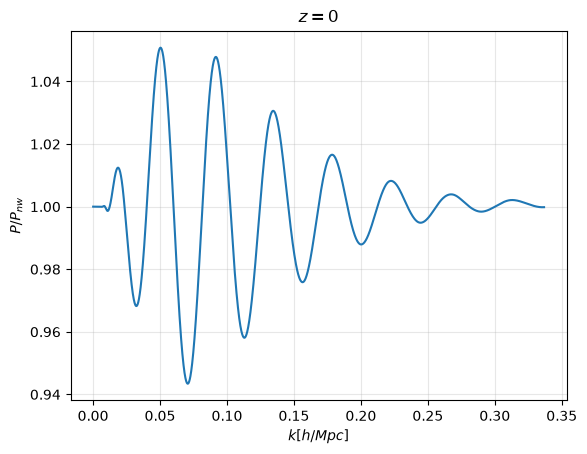

In [32]:
kh = np.logspace(-4, np.log10(.5), 10000) #h*Mpc-1

pk_lin = lambda ks, z: np.array([cosmo.pk_lin(k, z) for k in ks])
pk_lin_noob = lambda ks, z: np.array([cosmo_noob.pk_numerical_nw(k, z) for k in ks])

fig, ax = plt.subplots()

ax.plot(kh*h, pk_lin(kh*h, z = 0)/pk_lin_noob(kh*h, z = 0))
ax.set(ylabel = r'$P/P_{nw}$', xlabel = r'$k [h/Mpc]$',
       title = r'$z = 0$')
ax.grid(alpha = .3)

fig.savefig('oscilanciones_bariones.png', bbox_inches = 'tight')